# Exploración de la demanda histórica — Los Finos ERP

## A. Objetivo y alcance

Este cuaderno prepara y explora el historial de ventas diarias por producto que se usará más adelante para la planificación de demanda.

- **Datos sintéticos:** el lote `LF-DEMANDA-V1` fue generado por una carga de simulación (vista `dbo.LFSim_DemandaDiaria`). Los resultados posteriores demostrarán el **método**; no acreditan precisión sobre ventas reales.
- **Esta entrega:** conexión de solo lectura, validación de calidad, exploración y separación temporal. **No se entrena ningún modelo** y no hay conexión con el frontend.
- **Fuente única:** `dbo.LFSim_DemandaDiaria`. No se mezclan pedidos nuevos de la aplicación ni se modifica la base de datos.

## B. Entorno

In [2]:
import sys
from pathlib import Path

# Localiza python/src sin depender del directorio desde el que se abrió JupyterLab.
_base = Path.cwd().resolve()
_candidatos = [b / r for b in (_base, *_base.parents) for r in ("src", "python/src")]
_src = next(c for c in _candidatos if (c / "losfinos_demanda").is_dir())
if str(_src) not in sys.path:
    sys.path.insert(0, str(_src))

import platform
from importlib.metadata import version

print("Python    :", platform.python_version())
for paquete in ["pandas", "numpy", "matplotlib", "seaborn", "SQLAlchemy", "pyodbc"]:
    print(f"{paquete:<10}:", version(paquete))

Python    : 3.11.18
pandas    : 3.1.0
numpy     : 2.4.6
matplotlib: 3.11.2
seaborn   : 0.13.2
SQLAlchemy: 2.1.6
pyodbc    : 5.3.0


## C. Carga

Se consulta únicamente el lote `LF-DEMANDA-V1` con una consulta parametrizada, ordenada por `Fecha` y `ProductoID`. La conexión es de solo lectura (autenticación integrada de Windows).

In [3]:
import pandas as pd
import matplotlib.pyplot as plt
from IPython.display import display

from losfinos_demanda import config, datos, graficos

graficos.estilo()
pd.set_option("display.max_columns", 30, "display.width", 200, "display.max_colwidth", 120)

engine = config.crear_engine()
config.probar_conexion(engine)
df = datos.cargar_demanda_diaria(engine, datos.LOTE_POR_DEFECTO)

print(f"Filas: {len(df):,} | Columnas: {df.shape[1]} | Fecha: {df['Fecha'].min().date()} → {df['Fecha'].max().date()}")
print("Tipo de Fecha:", df["Fecha"].dtype)
display(df.head(10))

Filas: 1,830 | Columnas: 14 | Fecha: 2026-04-29 → 2026-10-28
Tipo de Fecha: datetime64[s]


,LoteID,Lote,Fecha,ProductoID,NombreProducto,CategoriaID,DiaSemana,Mes,Disponible,PrecioSimulado,UnidadesVendidas,UnidadesAnuladas,ImporteVendido,EsSintetico
0,1,LF-DEMANDA-V1,2026-04-29,1,Lomo Saltado Criollo,1,3,4,True,25.0,7,2,175.0,True
1,1,LF-DEMANDA-V1,2026-04-29,2,Arroz Chaufa Especial de Pollo,1,3,4,True,24.0,7,0,168.0,True
2,1,LF-DEMANDA-V1,2026-04-29,3,Tallarín Saltado Criollo de Carne,1,3,4,True,19.0,3,0,57.0,True
3,1,LF-DEMANDA-V1,2026-04-29,4,Porción de Alitas Broaster (8 und),2,3,4,True,22.0,5,0,110.0,True
4,1,LF-DEMANDA-V1,2026-04-29,5,Mostrito Los Finos,2,3,4,True,20.0,5,0,100.0,True
5,1,LF-DEMANDA-V1,2026-04-29,6,Menú Diario: Estofado de Pollo,3,3,4,True,10.0,6,0,60.0,True
6,1,LF-DEMANDA-V1,2026-04-29,7,Menú Diario: Pollo al Sillao,3,3,4,False,13.0,0,0,0.0,True
7,1,LF-DEMANDA-V1,2026-04-29,8,Jarra de Chicha Morada (1 Litro),4,3,4,True,12.0,4,0,48.0,True
8,1,LF-DEMANDA-V1,2026-04-29,9,Inca Kola 500ml,4,3,4,True,4.5,4,0,18.0,True
9,1,LF-DEMANDA-V1,2026-04-29,10,Porción de Papas Fritas Familiares,5,3,4,True,10.0,1,0,10.0,True


## D. Validación

Cada control devuelve un nivel: **ok**, **info**, **revisar** (diferencia respecto a lo esperado, para revisión humana) o **error** (impide continuar). No se eliminan filas con cero ventas ni se corrige ningún valor.

In [17]:
validacion = datos.validar_demanda(df)
estilos = {"ok": "background-color:#0A5726", "info": "background-color:#570A29",
           "revisar": "background-color:#fff3d6", "error": "background-color:#fbe0dd"}
display(validacion.style.apply(lambda fila: [estilos[fila["Nivel"]]] * len(fila), axis=1).hide(axis="index"))
print(validacion["Nivel"].value_counts().to_dict())

Control,Nivel,Detalle
Columnas obligatorias,ok,Presentes las 14 columnas.
Lote único,ok,Un solo lote: LF-DEMANDA-V1.
Sin duplicados Fecha+Producto,ok,0 duplicados.
Sin nulos en campos esenciales,ok,0 nulos.
Cobertura diaria y por producto,ok,"183 días × 10 productos = 1830 filas, sin huecos."
UnidadesVendidas: enteros no negativos,ok,Valores válidos.
UnidadesAnuladas: enteros no negativos,ok,Valores válidos.
Disponible solo 0/1,ok,Valores 0/1.
Sin ventas con Disponible=0,ok,Coherente.
ImporteVendido = Unidades × Precio,ok,Coherente (tolerancia 0.011).


{'ok': 19, 'info': 1}


In [5]:
# Se detiene aquí solo si hay errores bloqueantes.
datos.exigir_sin_errores(validacion)
revisar = validacion[validacion["Nivel"] == "revisar"]
print("Validación sin errores bloqueantes." if revisar.empty else f"Hay {len(revisar)} control(es) a revisar:")
display(revisar)

Validación sin errores bloqueantes.


,Control,Nivel,Detalle


## E. Exploración

Este dataset representa **productos vendidos**, no consumo de insumos: no se suman kilogramos, litros ni unidades de insumos. La vista no contiene `CanalID`, por lo que no se analiza por canal. Los productos 1–7 son platos; el resto son bebidas y extras y se cuentan aparte.

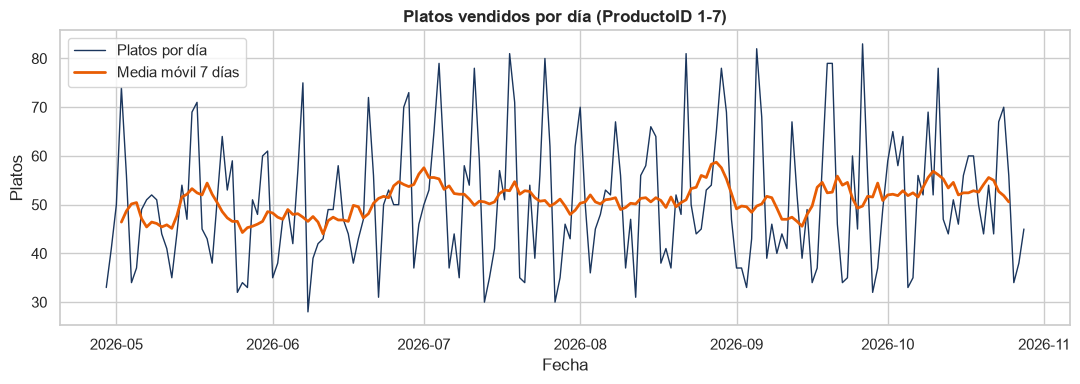

In [6]:
fig = graficos.serie_diaria_platos(df); plt.show()

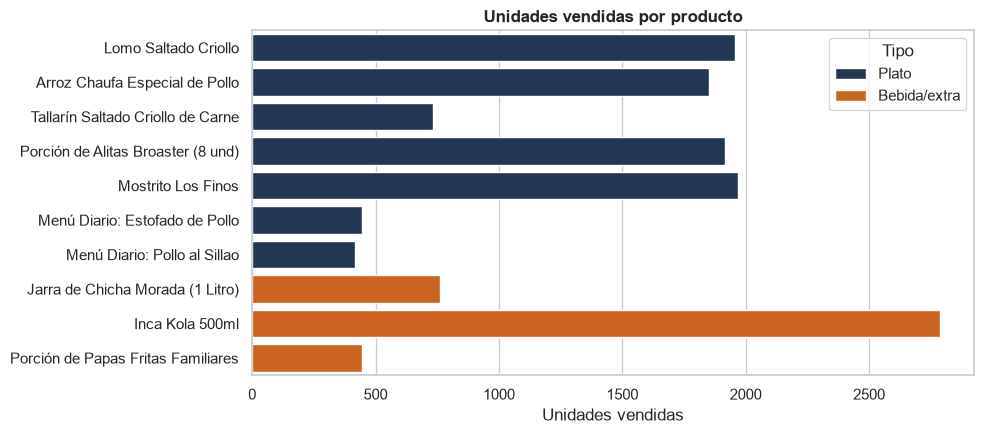

In [7]:
fig = graficos.unidades_por_producto(df); plt.show()

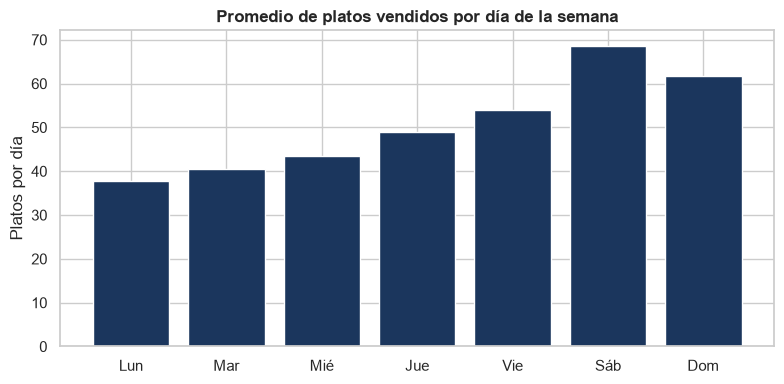

In [8]:
fig = graficos.promedio_por_dia_semana(df); plt.show()

Los menús 6 y 7 alternan su disponibilidad: los días en que un menú no está disponible no tiene ventas (se comprobó en la validación).

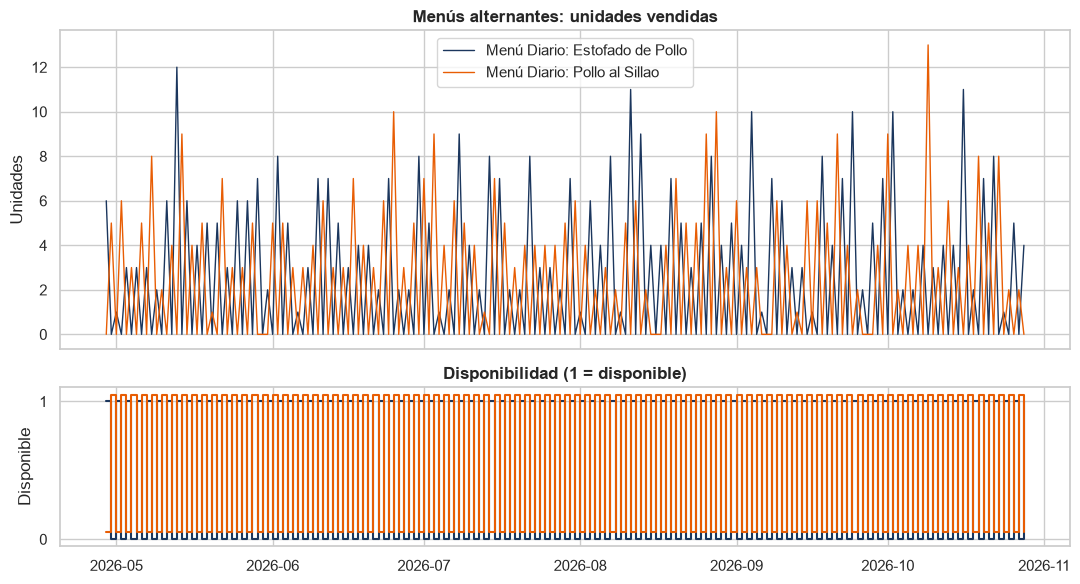

,ProductoID,NombreProducto,DiasDisponible,DiasNoDisponible,UnidadesVendidas
0,6,Menú Diario: Estofado de Pollo,92,91,443
1,7,Menú Diario: Pollo al Sillao,91,92,417


In [9]:
fig = graficos.menus_y_disponibilidad(df); plt.show()
display(graficos.resumen_menus(df))

**Resumen mensual.** Abril (desde el 29/04) y octubre (hasta el 28/10) son **meses parciales**: sus totales no son comparables con los de los meses completos.

In [10]:
display(datos.resumen_mensual(df))

,Dias,UnidadesVendidas,PlatosVendidos,MesParcial
Periodo,,,,
2026-04,2,100,74,True
2026-05,31,2181,1531,False
2026-06,30,2089,1458,False
2026-07,31,2302,1613,False
2026-08,31,2362,1638,False
2026-09,30,2115,1481,False
2026-10,28,2125,1487,True


## F. Separación temporal

- **Desarrollo:** 29/04/2026 – 30/09/2026.
- **Prueba final reservada:** 01/10/2026 – 28/10/2026.

La prueba final **no se usa** para entrenar, ajustar parámetros ni seleccionar modelos. La validación de modelos se hará posteriormente **dentro** del período de desarrollo.

In [11]:
desarrollo, prueba = datos.separar_temporal(df)
display(datos.resumen_separacion(desarrollo, prueba))
assert len(desarrollo) + len(prueba) == len(df), "La separación debe cubrir todo el historial sin solaparse."
assert desarrollo["Fecha"].max() < prueba["Fecha"].min()

,Conjunto,Desde,Hasta,Días,Filas
0,Desarrollo,2026-04-29,2026-09-30,155,1550
1,Prueba final (reservada),2026-10-01,2026-10-28,28,280


## G. Conclusiones de preparación

Los resultados de arriba permiten resumir:

- Los controles de calidad (D) indican si el lote es consistente y si coincide con las cifras esperadas; cualquier diferencia queda marcada como *revisar*.
- Se conservaron los días de cero ventas y se respetó la disponibilidad de los menús 6 y 7.
- Los datos son sintéticos, de un solo lote y con ~6 meses de historia: no sustentan conclusiones de negocio ni precisión predictiva.
- No hay detalle por canal en esta vista y abril/octubre son meses parciales.
- **Siguiente etapa:** definir y entrenar modelos con validación temporal dentro del período de desarrollo, reservando la prueba final para la evaluación definitiva.